## 1. Carregamento e visão geral dos dados

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/bike_sharing.csv")


In [29]:
df.head()


,Date,Rented_Bike_Count,Hour,Temperature,Humidity,Wind_Speed,Visibility,Dew_Point_Temperature,Solar_Radiation,Rainfall,Snowfall,Seasons,Holiday,Functioning_Day,Rain_Status,Snow_Status,Day_of_Week,Month
0,2018-10-18,165,4,8.1,78,0.6,2000,4.4,0.00,0.0,0.0,Autumn,No Holiday,Yes,Sem chuva,Sem neve,Thursday,10
1,2018-03-30,115,4,9.9,67,1.1,820,4.0,0.00,0.0,0.0,Spring,No Holiday,Yes,Sem chuva,Sem neve,Friday,3
2,2017-12-19,55,5,-3.9,66,0.7,1209,-9.3,0.00,0.0,2.6,Winter,No Holiday,Yes,Sem chuva,Com neve,Tuesday,12
3,2018-05-05,1024,11,20.2,41,3.1,1789,6.5,2.56,0.0,0.0,Spring,No Holiday,Yes,Sem chuva,Sem neve,Saturday,5
4,2018-04-24,157,1,10.1,83,1.6,2000,7.3,0.00,0.0,0.0,Spring,No Holiday,Yes,Sem chuva,Sem neve,Tuesday,4


In [31]:
print("Shape:", df.shape)
print("\nColunas:")
print(df.columns.tolist())
print("\nTipos:")
print(df.dtypes)


Shape: (7008, 14)

Colunas:
['Date', 'Rented_Bike_Count', 'Hour', 'Temperature', 'Humidity', 'Wind_Speed', 'Visibility', 'Dew_Point_Temperature', 'Solar_Radiation', 'Rainfall', 'Snowfall', 'Seasons', 'Holiday', 'Functioning_Day']

Tipos:
Date                      object
Rented_Bike_Count          int64
Hour                       int64
Temperature              float64
Humidity                   int64
Wind_Speed               float64
Visibility                 int64
Dew_Point_Temperature    float64
Solar_Radiation          float64
Rainfall                 float64
Snowfall                 float64
Seasons                   object
Holiday                   object
Functioning_Day           object
dtype: object


In [5]:
df.info()
display(df.describe().T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7008 entries, 0 to 7007
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Date                   7008 non-null   object 
 1   Rented_Bike_Count      7008 non-null   int64  
 2   Hour                   7008 non-null   int64  
 3   Temperature            7008 non-null   float64
 4   Humidity               7008 non-null   int64  
 5   Wind_Speed             7008 non-null   float64
 6   Visibility             7008 non-null   int64  
 7   Dew_Point_Temperature  7008 non-null   float64
 8   Solar_Radiation        7008 non-null   float64
 9   Rainfall               7008 non-null   float64
 10  Snowfall               7008 non-null   float64
 11  Seasons                7008 non-null   object 
 12  Holiday                7008 non-null   object 
 13  Functioning_Day        7008 non-null   object 
dtypes: float64(6), int64(4), object(4)
memory usage: 766.6+ 

,count,mean,std,min,25%,50%,75%,max
Rented_Bike_Count,7008.0,704.974315,643.821404,0.0,195.000,504.50,1066.00,3556.00
Hour,7008.0,11.505565,6.910752,0.0,6.000,11.00,17.00,23.00
Temperature,7008.0,12.913413,11.943094,-17.8,3.500,13.90,22.50,39.40
Humidity,7008.0,58.266124,20.251060,0.0,43.000,57.00,74.00,98.00
Wind_Speed,7008.0,1.729894,1.038611,0.0,0.975,1.50,2.30,7.40
Visibility,7008.0,1434.956193,608.915771,27.0,935.750,1690.00,2000.00,2000.00
Dew_Point_Temperature,7008.0,4.115411,13.076265,-30.6,-4.500,5.10,14.90,26.80
Solar_Radiation,7008.0,0.573182,0.872598,0.0,0.000,0.01,0.93,3.52
Rainfall,7008.0,0.137728,1.014356,0.0,0.000,0.00,0.00,29.50
Snowfall,7008.0,0.078082,0.446350,0.0,0.000,0.00,0.00,8.80


### Observações

O conjunto possui **7.008 observações e 14 variáveis**. Cada linha representa uma hora registrada no sistema de bicicletas.

A variável de interesse é **`Rented_Bike_Count`**, que representa a quantidade de bicicletas alugadas naquela hora. As demais variáveis descrevem horário, condições meteorológicas, estação do ano, feriado e funcionamento do serviço.


## 2. Verificação da qualidade dos dados

In [6]:
# Objetivo: verificar valores ausentes e registros duplicados.
print("Valores ausentes por coluna:")
display(df.isna().sum().to_frame("missing"))

print("\nQuantidade de linhas duplicadas:", df.duplicated().sum())


Valores ausentes por coluna:


,missing
Date,0
Rented_Bike_Count,0
Hour,0
Temperature,0
Humidity,0
Wind_Speed,0
Visibility,0
Dew_Point_Temperature,0
Solar_Radiation,0
Rainfall,0



Quantidade de linhas duplicadas: 0


### Observações

Não foram identificados valores ausentes nem registros duplicados. Portanto, não foi necessário realizar remoção ou imputação de valores nesta etapa.


In [7]:
categoricas = ["Seasons", "Holiday", "Functioning_Day"]

for coluna in categoricas:
    print(f"\n{coluna}")
    display(df[coluna].value_counts().to_frame("count"))



Seasons


,count
Seasons,
Summer,1767
Spring,1766
Autumn,1747
Winter,1728



Holiday


,count
Holiday,
No Holiday,6660
Holiday,348



Functioning_Day


,count
Functioning_Day,
Yes,6774
No,234


### Observações sobre as categorias

 As quatro estações possuem quantidades de observações semelhantes.

 A variável `Holiday` é desbalanceada: há muito mais registros de dias comuns do que de feriados.

 `Functioning_Day = No` ocorre em uma parcela pequena dos registros e merece atenção, pois pode explicar observações com demanda igual a zero.


## 3. Distribuição da demanda

In [8]:
# Objetivo: resumir estatisticamente a variável de demanda.
demanda = df["Rented_Bike_Count"]

print(f"Média: {demanda.mean():.2f}")
print(f"Mediana: {demanda.median():.2f}")
print(f"Desvio padrão: {demanda.std():.2f}")
print(f"Variância: {demanda.var():.2f}")
print(f"Assimetria: {demanda.skew():.2f}")
print("\nQuartis:")
display(demanda.quantile([0.25, 0.50, 0.75]).to_frame("Rented_Bike_Count"))


Média: 704.97
Mediana: 504.50
Desvio padrão: 643.82
Variância: 414506.00
Assimetria: 1.15

Quartis:


,Rented_Bike_Count
0.25,195.0
0.50,504.5
0.75,1066.0


### Interpretação das medidas

A média da demanda é aproximadamente **705 bicicletas**, enquanto a mediana é aproximadamente **505**. Como a média é maior que a mediana e a assimetria é positiva (aproximadamente **1,15**), a distribuição apresenta uma cauda  a direita.

Isso indica a presença de períodos com demanda especialmente elevada, que puxam a média para cima.


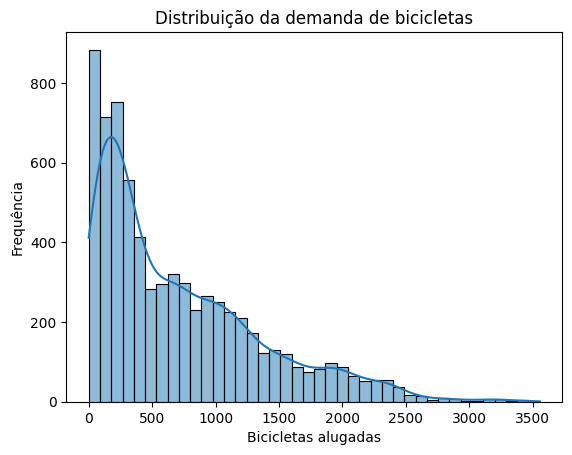

In [9]:
# Objetivo: visualizar a distribuição da demanda com um histograma.
sns.histplot(
    data=df,
    x="Rented_Bike_Count",
    kde=True
)

plt.title("Distribuição da demanda de bicicletas")
plt.xlabel("Bicicletas alugadas")
plt.ylabel("Frequência")
plt.show()


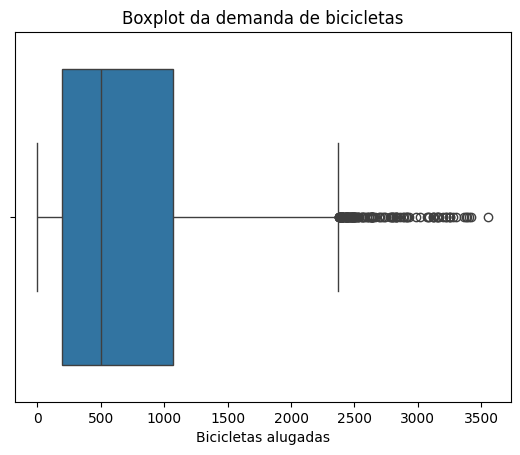

In [10]:
# Objetivo: visualizar a dispersão e potenciais valores extremos da demanda.
sns.boxplot(
    data=df,
    x="Rented_Bike_Count"
)

plt.title("Boxplot da demanda de bicicletas")
plt.xlabel("Bicicletas alugadas")
plt.show()


### Interpretação dos gráficos

O histograma confirma a assimetria positiva observada nas medidas descritivas. O boxplot apresenta valores elevados classificados visualmente como potenciais *outliers*.

Esses valores **não serão removidos automaticamente**, pois podem representar horários reais de grande demanda e não necessariamente erros de coleta. Uma remoção exigiria uma justificativa baseada nos dados.


## 4. Fatores relacionados à demanda

In [11]:
# reutilizavel.
def resumo_demanda_por_grupo(data, coluna):
    """Retorna contagem, média e mediana da demanda agrupadas por uma coluna."""
    return (
        data.groupby(coluna)["Rented_Bike_Count"]
        .agg(["count", "mean", "median"])
    )


### 4.1 Funcionamento do sistema

In [12]:
# verifica se as observações com demanda zero coincidem com dias sem funcionamento.
pd.crosstab(
    df["Functioning_Day"],
    df["Rented_Bike_Count"] == 0,
    rownames=["Functioning_Day"],
    colnames=["Rented_Bike_Count = 0"]
)


Rented_Bike_Count = 0,False,True
Functioning_Day,,
No,0,234
Yes,6774,0


In [13]:
# comparar a demanda entre períodos com e sem funcionamento do sistema.
resumo_demanda_por_grupo(df, "Functioning_Day")


,count,mean,median
Functioning_Day,,,
No,234,0.000000,0.0
Yes,6774,729.326838,540.5


### Interpretação

Existem 234 registros com demanda igual a zero, e todos correspondem a períodos em que `Functioning_Day = No`.

Portanto, esses zeros não devem ser interpretados apenas como horários de baixa procura: representam períodos em que o serviço **não estava disponível**.


### 4.2 Horário do dia

,Hour,Rented_Bike_Count
0,0,540.357860
1,1,433.433566
2,2,312.127208
3,3,204.933099
4,4,133.472603
5,5,141.704082
6,6,292.061224
7,7,607.843333
8,8,1057.508772
9,9,658.205298


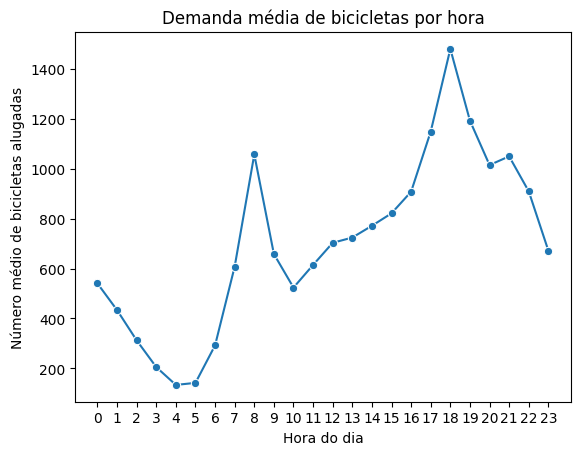

In [14]:

demanda_hora = (
    df.groupby("Hour")["Rented_Bike_Count"]
    .mean()
    .reset_index()
)

display(demanda_hora)

sns.lineplot(
    data=demanda_hora,
    x="Hour",
    y="Rented_Bike_Count",
    marker="o"
)

plt.title("Demanda média de bicicletas por hora")
plt.xlabel("Hora do dia")
plt.ylabel("Número médio de bicicletas alugadas")
plt.xticks(range(24))
plt.show()


### Interpretação

A demanda varia fortemente ao longo do dia. Os menores valores aparecem durante a madrugada, enquanto se observam picos por volta das 8h e principalmente entre 17h e 21h.

O maior valor médio ocorre aproximadamente às **18h**, sugerindo que o horário do dia possui uma relação importante com a utilização do sistema. O formato da curva também mostra que essa relação não é simplesmente linear.


### 4.3 Temperatura

In [15]:
#calcular a correlação linear entre temperatura e demanda.
df[["Temperature", "Rented_Bike_Count"]].corr()


,Temperature,Rented_Bike_Count
Temperature,1.000000,0.534836
Rented_Bike_Count,0.534836,1.000000


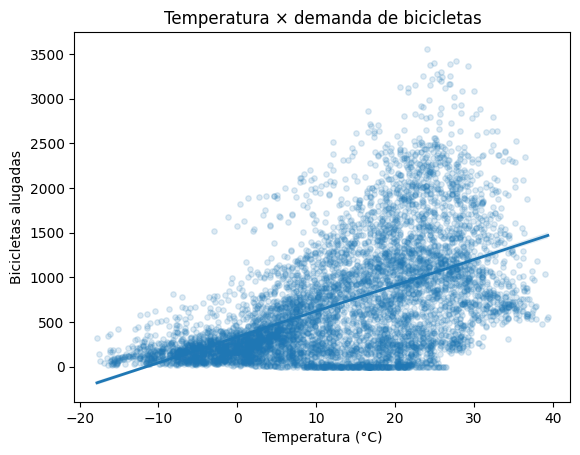

In [16]:
# visualizar a relação entre temperatura e demanda.
sns.regplot(
    data=df,
    x="Temperature",
    y="Rented_Bike_Count",
    scatter_kws={"alpha": 0.15, "s": 15},
    line_kws={"linewidth": 2}
)

plt.title("Temperatura × demanda de bicicletas")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Bicicletas alugadas")
plt.show()


### Interpretação

A temperatura apresenta correlação positiva moderada com a demanda (**r ≈ 0,53**). O gráfico sugere que temperaturas maiores estão associadas, em geral, a maiores quantidades de bicicletas alugadas.

Entretanto, existe bastante dispersão, indicando que a temperatura isoladamente não explica todo o comportamento da demanda.


### 4.4 Estações do ano

In [17]:
#comparar quantitativamente a demanda entre as quatro estações.
resumo_estacoes = resumo_demanda_por_grupo(df, "Seasons").sort_values(
    "mean",
    ascending=False
)

resumo_estacoes


,count,mean,median
Seasons,,,
Summer,1767,1022.923033,901.0
Autumn,1747,825.668575,763.0
Spring,1766,737.215176,587.0
Winter,1728,224.878472,203.5


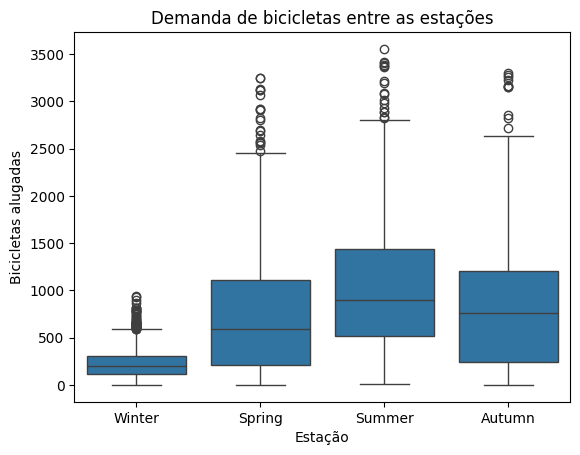

In [18]:
# comparar visualmente a distribuição da demanda entre as estações.
ordem = ["Winter", "Spring", "Summer", "Autumn"]

sns.boxplot(
    data=df,
    x="Seasons",
    y="Rented_Bike_Count",
    order=ordem
)

plt.title("Demanda de bicicletas entre as estações")
plt.xlabel("Estação")
plt.ylabel("Bicicletas alugadas")
plt.show()


### Interpretação

A demanda apresenta diferenças visíveis entre as estações. O verão possui a maior demanda média, com aproximadamente 1.023 bicicletas por hora, enquanto o inverno apresenta cerca de 225.




### 4.5 Chuva

In [19]:
# criar uma variável indicando presença ou ausência de chuva.
df["Rain_Status"] = df["Rainfall"].gt(0).map({
    True: "Com chuva",
    False: "Sem chuva"
})

resumo_chuva = resumo_demanda_por_grupo(df, "Rain_Status")
resumo_chuva


,count,mean,median
Rain_Status,,,
Com chuva,418,164.550239,66.5
Sem chuva,6590,739.253111,561.0


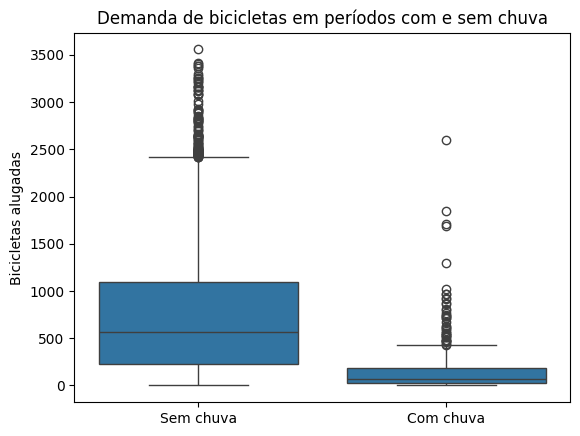

In [20]:
#  comparar visualmente a demanda em períodos com e sem chuva.
sns.boxplot(
    data=df,
    x="Rain_Status",
    y="Rented_Bike_Count"
)

plt.title("Demanda de bicicletas em períodos com e sem chuva")
plt.xlabel("")
plt.ylabel("Bicicletas alugadas")
plt.show()


### Interpretação

Nos períodos sem chuva, a demanda média é de aproximadamente 739 bicicletas, enquanto nos períodos com chuva a média cai para aproximadamente 165.




### 4.6 Neve

In [21]:
#  criar uma variável indicando presença ou ausência de neve.
df["Snow_Status"] = df["Snowfall"].gt(0).map({
    True: "Com neve",
    False: "Sem neve"
})

resumo_neve = resumo_demanda_por_grupo(df, "Snow_Status")
resumo_neve


,count,mean,median
Snow_Status,,,
Com neve,367,187.915531,149.0
Sem neve,6641,733.548411,558.0


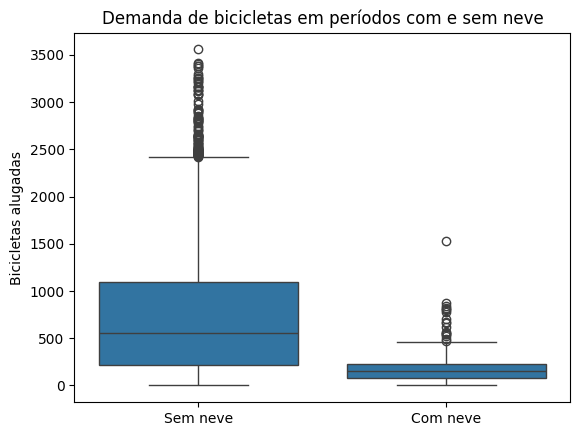

In [22]:
#  comparar visualmente a demanda em períodos com e sem neve.
sns.boxplot(
    data=df,
    x="Snow_Status",
    y="Rented_Bike_Count"
)

plt.title("Demanda de bicicletas em períodos com e sem neve")
plt.xlabel("")
plt.ylabel("Bicicletas alugadas")
plt.show()


### Interpretação

A demanda média também é consideravelmente menor nos períodos em que há registro de neve: aproximadamente 188 bicicletas, contra cerca de 734 nos períodos sem neve.




### 4.7 Feriados

In [23]:
# Objetivo: comparar quantitativamente a demanda entre feriados e dias comuns.
resumo_feriado = resumo_demanda_por_grupo(df, "Holiday")
resumo_feriado


,count,mean,median
Holiday,,,
Holiday,348,498.471264,240.0
No Holiday,6660,715.764565,524.5


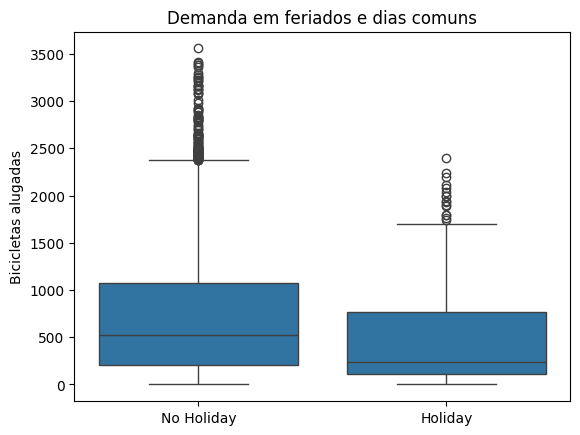

In [24]:
# Objetivo: comparar visualmente a demanda em feriados e dias comuns.
sns.boxplot(
    data=df,
    x="Holiday",
    y="Rented_Bike_Count"
)

plt.title("Demanda em feriados e dias comuns")
plt.xlabel("")
plt.ylabel("Bicicletas alugadas")
plt.show()


### Interpretação

A demanda média é de aproximadamente 498 bicicletas em feriados e 716 em dias comuns.

Entretanto, os grupos são bastante desbalanceados: existem apenas 348 registros de feriados, contra 6.660 registros de dias comuns. Portanto, a diferença observada é interessante, mas ainda não deve ser tratada como evidência estatística definitiva.


### 4.8 Dia da semana

,mean
Day_of_Week,
Monday,742.094433
Tuesday,671.252243
Wednesday,748.393725
Thursday,697.649105
Friday,752.275202
Saturday,702.719488
Sunday,621.042126


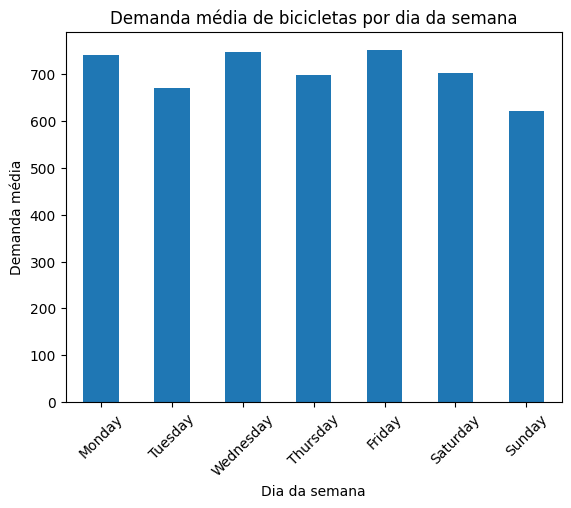

In [25]:
# transformar a data e comparar a demanda média ao longo dos dias da semana.
df["Date"] = pd.to_datetime(
    df["Date"],
    format="%d/%m/%Y"
)

df["Day_of_Week"] = df["Date"].dt.day_name()
df["Month"] = df["Date"].dt.month

ordem_dias = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

demanda_dia = (
    df.groupby("Day_of_Week")["Rented_Bike_Count"]
    .mean()
    .reindex(ordem_dias)
)

display(demanda_dia.to_frame("mean"))

demanda_dia.plot(kind="bar")
plt.title("Demanda média de bicicletas por dia da semana")
plt.xlabel("Dia da semana")
plt.ylabel("Demanda média")
plt.xticks(rotation=45)
plt.show()


### Interpretação

A criação de `Day_of_Week` a partir da coluna `Date` permite investigar um padrão que não estava explicitamente disponível no conjunto original.




### 4.9 Hora × estação

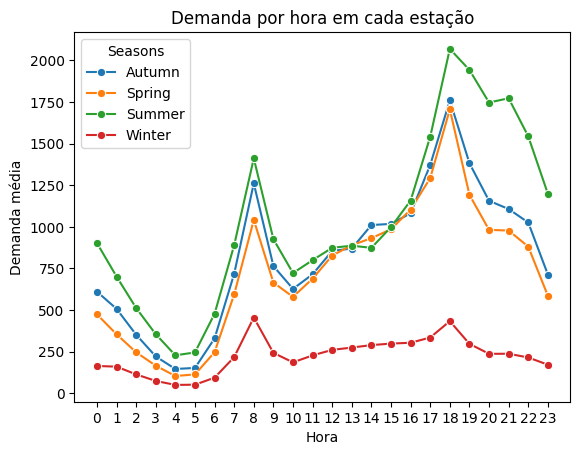

In [26]:
#  comparar o padrão horário da demanda entre as estações do ano.
demanda_hora_estacao = (
    df.groupby(["Hour", "Seasons"])["Rented_Bike_Count"]
    .mean()
    .reset_index()
)

sns.lineplot(
    data=demanda_hora_estacao,
    x="Hour",
    y="Rented_Bike_Count",
    hue="Seasons",
    marker="o"
)

plt.title("Demanda por hora em cada estação")
plt.xlabel("Hora")
plt.ylabel("Demanda média")
plt.xticks(range(24))
plt.show()


### Interpretação

O gráfico combina duas dimensões importantes da análise: horário e estação do ano.

Além das diferenças gerais entre as estações, é possível observar como o padrão diário de uso se modifica ao longo do ano. Essa visualização ajuda a perceber relações que uma análise de uma única variável não mostraria.


## 5. Análise de correlação

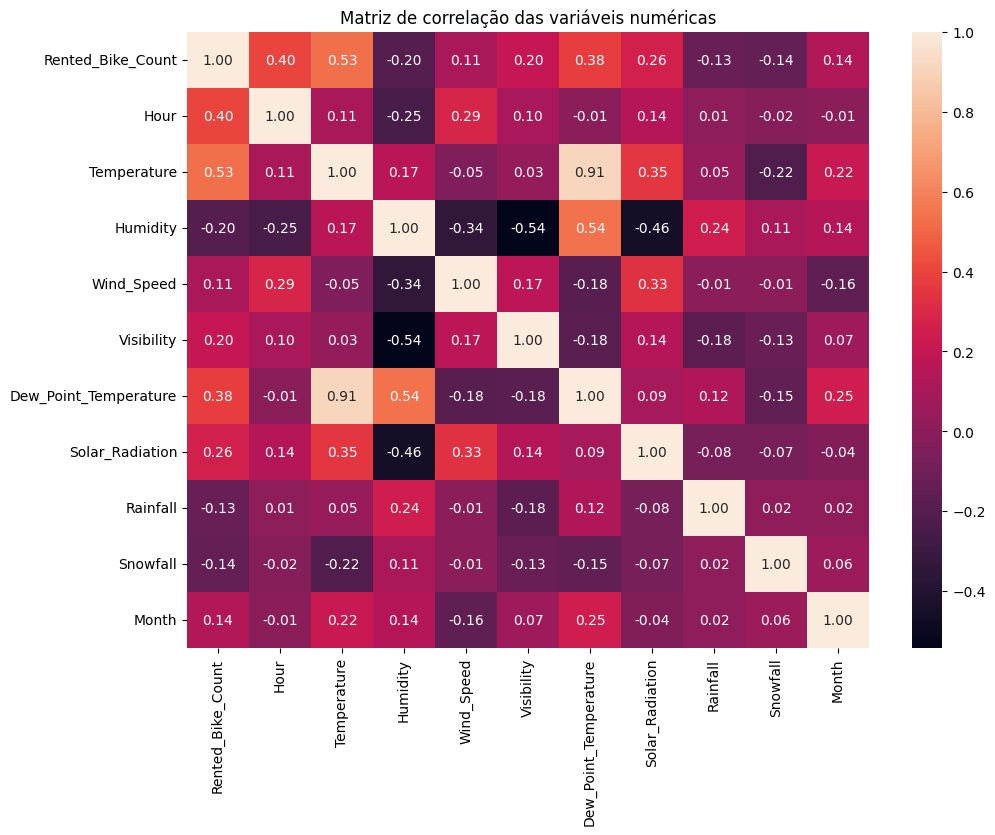

In [27]:
# visualizar a matriz de correlação entre todas as variáveis numéricas.
corr = df.select_dtypes("number").corr()

plt.figure(figsize=(11, 8))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f"
)

plt.title("Matriz de correlação das variáveis numéricas")
plt.show()


A matriz completa permite observar relações entre todas as variáveis numéricas, mas contém bastante informação. Para facilitar a interpretação com foco no objetivo do trabalho, o gráfico seguinte mostra apenas a correlação de cada variável numérica com `Rented_Bike_Count`.


,correlation
Humidity,-0.197937
Snowfall,-0.143841
Rainfall,-0.129914
Wind_Speed,0.112632
Month,0.137773
Visibility,0.200646
Solar_Radiation,0.263064
Dew_Point_Temperature,0.378105
Hour,0.399705
Temperature,0.534836


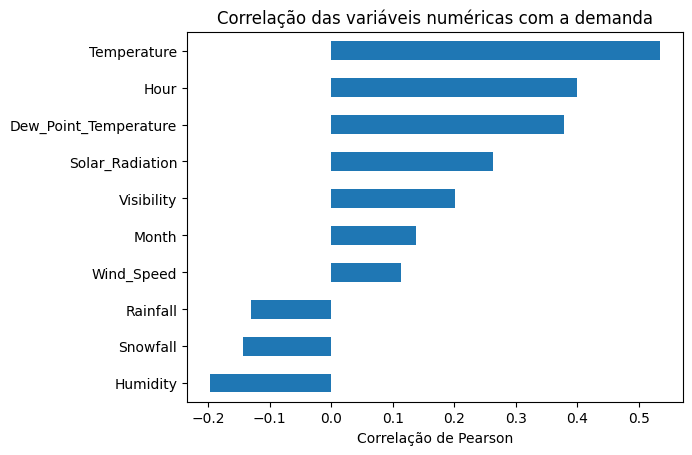

In [28]:
#  ordenar as correlações das variáveis numéricas com a demanda.
corr_demanda = (
    df.select_dtypes("number")
    .corr()["Rented_Bike_Count"]
    .drop("Rented_Bike_Count")
    .sort_values()
)

display(corr_demanda.to_frame("correlation"))

corr_demanda.plot(kind="barh")
plt.title("Correlação das variáveis numéricas com a demanda")
plt.xlabel("Correlação de Pearson")
plt.ylabel("")
plt.show()


### Interpretação

Entre as variáveis numéricas, a **temperatura** apresenta a maior correlação linear positiva com a demanda (aproximadamente **0,53**). `Hour` e `Dew_Point_Temperature` também apresentam associações positivas relevantes.

`Humidity`, `Rainfall` e `Snowfall` apresentam correlações negativas com a demanda.

Esses coeficientes descrevem **relações lineares** e não implicam causalidade. Além disso, algumas relações importantes podem ser não lineares, como observado no padrão da demanda ao longo das horas do dia.
